#Installing Dependencies

In [ ]:
import numpy as np

-Torchvision

 -Matplotlib

 -fasterrcnn

 -resnet50

 -Intersection over Union (IoU)

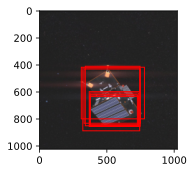

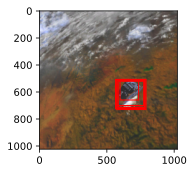

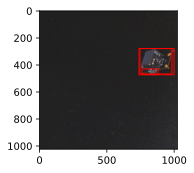

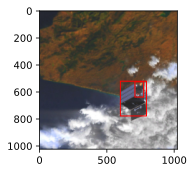

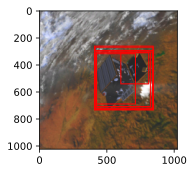

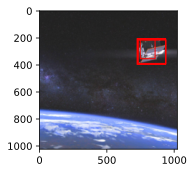

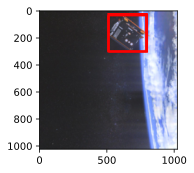

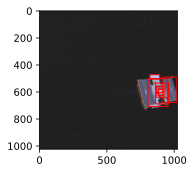

In [ ]:
import os
import torchvision
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

#pre-trained Faster R-CNN model
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)
model.eval()

#transformation to apply to each image
transform = transforms.Compose([transforms.ToTensor()])

# Function to perform object detection on a single image
def detect_objects(image_path):
    #preprocessing the image
    image = Image.open(image_path)
    image_tensor = transform(image).unsqueeze(0)  # Add batch dimension

    #perform inference
    with torch.no_grad():
        prediction = model(image_tensor)

    return image, prediction
    import numpy as np

import numpy as np
#defning function plot_image_with_boxes
def plot_image_with_boxes(image, prediction):
    image_np = np.array(image)  # Convert PIL image to NumPy array
    image_shape = image_np.shape

    # Determine the order of dimensions for matplotlib based on the shape of the image
    if len(image_shape) == 2:  # Grayscale image
        image_np = np.transpose(image_np, (0, 1))
    elif len(image_shape) == 3:  # RGB image
        if image_shape[0] == 3:  # Channels first
            image_np = np.transpose(image_np, (1, 2, 0))
        else:
            image_np = np.transpose(image_np, (0, 1, 2))
    else:
        raise ValueError("Unsupported image shape")

    fig, ax = plt.subplots(1)
    ax.imshow(image_np)

    for box in prediction[0]['boxes']:
        box = box.cpu().numpy()
        xmin, ymin, xmax, ymax = box
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                 linewidth=1, edgecolor='r', facecolor='none')
        ax.add_patch(rect)

    plt.show()

#load images from folder
folder_path = '/content/drive/MyDrive/Profile/Proba2_images'

# Iterate through all images available in the folder
for filename in os.listdir(folder_path):
  #file extension
    if filename.endswith('.jpg') or filename.endswith('.png'):
        image_path = os.path.join(folder_path, filename)
        image, prediction = detect_objects(image_path)
        plot_image_with_boxes(image, prediction)


In [ ]:
def calculate_iou(box1, box2):
    """Calculate Intersection over Union (IoU) between two bounding boxes."""
    xmin1, ymin1, xmax1, ymax1 = box1
    xmin2, ymin2, xmax2, ymax2 = box2

    # Calculate coordinates of intersection area
    xmin_intersect = max(xmin1, xmin2)
    ymin_intersect = max(ymin1, ymin2)
    xmax_intersect = min(xmax1, xmax2)
    ymax_intersect = min(ymax1, ymax2)

    # Calculate area of intersection rectangle
    intersect_area = max(0, xmax_intersect - xmin_intersect + 1) * max(0, ymax_intersect - ymin_intersect + 1)

    # Calculate area of each bounding box
    box1_area = (xmax1 - xmin1 + 1) * (ymax1 - ymin1 + 1)
    box2_area = (xmax2 - xmin2 + 1) * (ymax2 - ymin2 + 1)

    # Calculate IoU
    iou = intersect_area / float(box1_area + box2_area - intersect_area)

    return iou

# Example usage:
iou = calculate_iou([60.0, 45.0, 378.0, 516.0], [70.0, 50.0, 400.0, 500.0])
print("IoU:", iou)


IoU: 0.8683344756682659
